<a href="https://colab.research.google.com/github/muskankh/Satellite-vit-project/blob/main/04_robustness_retrieval_stats.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Satellite Image Classification with Vision Transformers
## Notebook 4: Robustness, Retrieval, Statistics and Embedding Visualisation

This notebook answers the question we have been building towards:

> **Do the models look at the actual land, or do they rely on shortcuts such as image resolution and colour?**

**What it does**
1. Loads the models: your **fine-tuned ViT** (saved by Notebook 3), **CLIP** and **DINOv2**
2. Creates **altered versions of the test images**: same resolution, greyscale, hue shift, darker, brighter
3. Runs all four methods (zero-shot CLIP, CLIP probe, DINOv2 probe, fine-tuned ViT) on every version
4. Measures how much accuracy drops, with paired bootstrap confidence intervals
5. Tests specifically for the **resolution shortcut** (do 256x256 classes get mistaken for 64x64 classes once the resolution cue is removed?)
6. **Statistical comparison** of the models (paired bootstrap and McNemar's exact test)
7. **Image retrieval** (image-to-image and CLIP text-to-image) with Precision@K
8. **UMAP** of the embeddings, coloured by class and by image size
9. Hard-case error gallery, then saves everything

**Why the same-resolution test matters:** in this dataset `cloudy` and `desert` images are 256x256, while `green_area` and `water` are 64x64. A model could cheat by recognising blur or resolution. If we shrink every test image to 64x64 and accuracy collapses, that shows the shortcut. If accuracy holds, the model learnt real content. Both outcomes are valid findings.

**You need a GPU** (Runtime -> T4 GPU). Expect about 10-20 minutes in total.

## 0. Setup and files

**Files you need** (drag into the Files panel, or keep in Google Drive under `My Drive/satellite_project/`):
| File | From | Needed for |
|---|---|---|
| `split.csv` | Notebook 1 | the same train/val/test split |
| `data-2.zip` | your data | the images |
| `vit_best_model/` folder (or `notebook3_outputs.zip`) | Notebook 3 | the fine-tuned ViT |
| `embeddings/*.npy` | Notebook 2 | optional, recomputed if missing |
| `results_notebook1/2/3.json`, `vit_test_predictions.csv` | Notebooks 1-3 | optional cross-checks |

Notebook 3 backed the model up to `My Drive/satellite_project/outputs_nb3/vit_best_model`, so if Drive is mounted it is found automatically.

**First run: set `QUICK_TEST = True`** in the config cell. It uses a small subset (a few minutes) to check that everything works. Then set it to `False` for the real run.

In [1]:
!pip install -q transformers scikit-learn matplotlib pandas tqdm umap-learn

In [2]:
import os, json, random, zipfile, shutil, time, math
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance
from tqdm.auto import tqdm
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# ---------------- CONFIG ----------------
QUICK_TEST = False        # True = small dry run to check the code works (results are meaningless)
SEED       = 42
WORK_DIR   = Path("/content/work")
OUT_DIR    = Path("/content/outputs_nb4")
DRIVE_BACKUP_DIR = Path("/content/drive/MyDrive/satellite_project")
N_BOOT     = 2000         # bootstrap resamples
# ----------------------------------------

FIG_DIR = OUT_DIR / "figures"
for d in (WORK_DIR, OUT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
if QUICK_TEST:
    print("*** QUICK TEST MODE: small subset. Do NOT use these results in your report. ***")

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab - skipping Drive mount.")
print("Setup OK")

Mounted at /content/drive
Setup OK


## 1. Load the split and images
Same loader as Notebooks 2-3, so every model is evaluated on the **identical test images**.

In [3]:
SEARCH_DIRS = ["/content", "/content/outputs", "/content/drive/MyDrive",
               "/content/drive/MyDrive/satellite_project", "/content/drive/MyDrive/Colab Notebooks"]

def find_file(patterns, what):
    for folder in SEARCH_DIRS:
        f = Path(folder)
        if not f.exists():
            continue
        for pat in patterns:
            hits = sorted(f.glob(pat))
            if hits:
                print(f"Found {what}: {hits[0]}")
                return hits[0]
    raise FileNotFoundError(
        f"Could not find {what}.\n"
        "FIX: click the folder icon on the LEFT of Colab, drag the file into the Files panel, "
        "wait for the upload to finish, then re-run this cell.")

SPLIT_CSV = find_file(["split.csv", "split*.csv"], "split.csv")
ZIP_FILE  = find_file(["data-2.zip", "data*.zip"], "your image zip")

EXTRACT_DIR = WORK_DIR / "images"

# 1) Unzip into a clean folder (skip Mac junk files). Re-extract if the folder is missing or has no images.
IMG_EXT = (".jpg", ".jpeg", ".png")
def list_images(folder):
    return [p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXT and not p.name.startswith("._")]

if EXTRACT_DIR.exists():
    shutil.rmtree(EXTRACT_DIR)          # always start clean: stale folders from failed attempts must not be reused
EXTRACT_DIR.mkdir(parents=True)
with zipfile.ZipFile(ZIP_FILE) as z:
    keep = [m for m in z.namelist()
            if not m.startswith("__MACOSX") and "/._" not in m and not m.endswith(".DS_Store")]
    z.extractall(EXTRACT_DIR, members=keep)

files = list_images(EXTRACT_DIR)
print("Image files found after unzipping:", len(files))
if not files:
    raise FileNotFoundError("The zip contains no images. Check that you uploaded the right zip file.")

# 2) Re-link every row of split.csv to the real file, wherever the zip put it
df = pd.read_csv(SPLIT_CSV)
index   = {(p.parent.name.lower(), p.name.lower()): p for p in files}      # (class folder, file name)
by_name = {}
for p in files:
    by_name.setdefault(p.name.lower(), []).append(p)

new_paths = []
for c, p in zip(df["cls"], df["path"]):
    name = Path(p).name.lower()
    hit = index.get((str(c).lower(), name))
    if hit is None and len(by_name.get(name, [])) == 1:                    # fall back to file name alone
        hit = by_name[name][0]
    new_paths.append(str(hit) if hit is not None else None)
df["path"] = new_paths

n_missing = int(df["path"].isna().sum())
if n_missing:
    print(f"\nPROBLEM: {n_missing} of {len(df)} images from split.csv were not found in the zip.")
    print("Folders in zip      :", sorted({p.parent.name for p in files})[:10])
    print("Example zip files   :", sorted(p.name for p in files)[:5])
    print("Example split.csv   :", [Path(p).name for p in pd.read_csv(SPLIT_CSV)["path"].head(5)])
    print("Zip file used       :", ZIP_FILE, f"({Path(ZIP_FILE).stat().st_size / 1e6:.1f} MB)")
    raise AssertionError("The zip does not match split.csv. Make sure you upload the SAME data-2.zip you used in Notebook 1 "
                         "(about 25 MB, 5,631 images), and delete any other data*.zip files from the Files panel.")

CLASS_NAMES = sorted(df["cls"].unique())
y = df["label"].values
idx_train = np.where(df["split"] == "train")[0]
idx_val   = np.where(df["split"] == "val")[0]
idx_test  = np.where(df["split"] == "test")[0]
print("Classes:", CLASS_NAMES)
print(f"train={len(idx_train)}  val={len(idx_val)}  test={len(idx_test)}   (Notebook 1 gave 3942 / 846 / 843)")
df[["cls", "split"]].value_counts().unstack()

Found split.csv: /content/drive/MyDrive/satellite_project/split.csv
Found your image zip: /content/drive/MyDrive/data-2.zip
Image files found after unzipping: 5631
Classes: ['cloudy', 'desert', 'green_area', 'water']
train=3942  val=846  test=843   (Notebook 1 gave 3942 / 846 / 843)


split,test,train,val
cls,,,
cloudy,225,1050,225
desert,170,788,173
green_area,225,1050,225
water,223,1054,223


In [4]:
if QUICK_TEST:
    df = (df.groupby(["cls", "split"], group_keys=False).sample(frac=0.12, random_state=SEED).reset_index(drop=True))
    y = df["label"].values
    idx_train = np.where(df["split"] == "train")[0]
    idx_val   = np.where(df["split"] == "val")[0]
    idx_test  = np.where(df["split"] == "test")[0]
    print(f"QUICK TEST subset: train={len(idx_train)} val={len(idx_val)} test={len(idx_test)}")

y_test = y[idx_test]
test_paths = df.loc[idx_test, "path"].tolist()
print("Test images:", len(idx_test))

# Native image size of each class (used later to detect the resolution shortcut)
NATIVE_W = df.groupby("cls")["width"].agg(lambda s: int(s.mode()[0]))
CLASS_GROUP = np.array([NATIVE_W[c] for c in CLASS_NAMES])      # e.g. [256, 256, 64, 64]
print("Native width per class:", dict(zip(CLASS_NAMES, CLASS_GROUP.tolist())))

def find_optional(name):
    folders = SEARCH_DIRS + ["/content/outputs_nb2", "/content/outputs_nb3", "/content/outputs_nb4",
                             "/content/drive/MyDrive/satellite_project/outputs_nb2",
                             "/content/drive/MyDrive/satellite_project/outputs_nb3"]
    for folder in folders:
        f = Path(folder) / name
        if f.exists():
            return f
    return None

Test images: 843
Native width per class: {'cloudy': 256, 'desert': 256, 'green_area': 64, 'water': 64}


## 2. The altered test images

| Variant | What we do | What it tests |
|---|---|---|
| **original** | nothing | reference |
| **same_res** | shrink every image to 64x64 (the 64x64 ones are untouched) | removes the resolution/sharpness cue |
| **grayscale** | remove colour | how much the model depends on colour |
| **hue_shift** | rotate all hues (+15%) | different sensor or season; colours move |
| **darker** | brightness x0.5 | dim or hazy imagery |
| **brighter** | brightness x1.5 | over-exposed imagery |

Each variant is applied to the **test images only**. The models are **not retrained** on them, because we want to see how fragile the trained models are. This is a robustness (stress) test, not a new training set.

In [5]:
def v_original(img):
    return img

def v_same_res(img):
    return img if img.size == (64, 64) else img.resize((64, 64), Image.LANCZOS)

def v_grayscale(img):
    return img.convert("L").convert("RGB")

def v_hue_shift(img, shift=0.15):
    h, s, v = img.convert("HSV").split()
    off = int(shift * 255)
    h = h.point(lambda x: (x + off) % 256)
    return Image.merge("HSV", (h, s, v)).convert("RGB")

def v_darker(img):
    return ImageEnhance.Brightness(img).enhance(0.5)

def v_brighter(img):
    return ImageEnhance.Brightness(img).enhance(1.5)

VARIANTS = {"original": v_original, "same_res": v_same_res, "grayscale": v_grayscale,
            "hue_shift": v_hue_shift, "darker": v_darker, "brighter": v_brighter}
VARIANT_NAMES = list(VARIANTS)

TEST_IMGS = {}
for vname, fn in VARIANTS.items():
    TEST_IMGS[vname] = [fn(Image.open(p).convert("RGB")) for p in tqdm(test_paths, desc=vname)]
print("Built", len(VARIANTS), "variants x", len(test_paths), "images")

original:   0%|          | 0/843 [00:00<?, ?it/s]

same_res:   0%|          | 0/843 [00:00<?, ?it/s]

grayscale:   0%|          | 0/843 [00:00<?, ?it/s]

hue_shift:   0%|          | 0/843 [00:00<?, ?it/s]

darker:   0%|          | 0/843 [00:00<?, ?it/s]

brighter:   0%|          | 0/843 [00:00<?, ?it/s]

Built 6 variants x 843 images


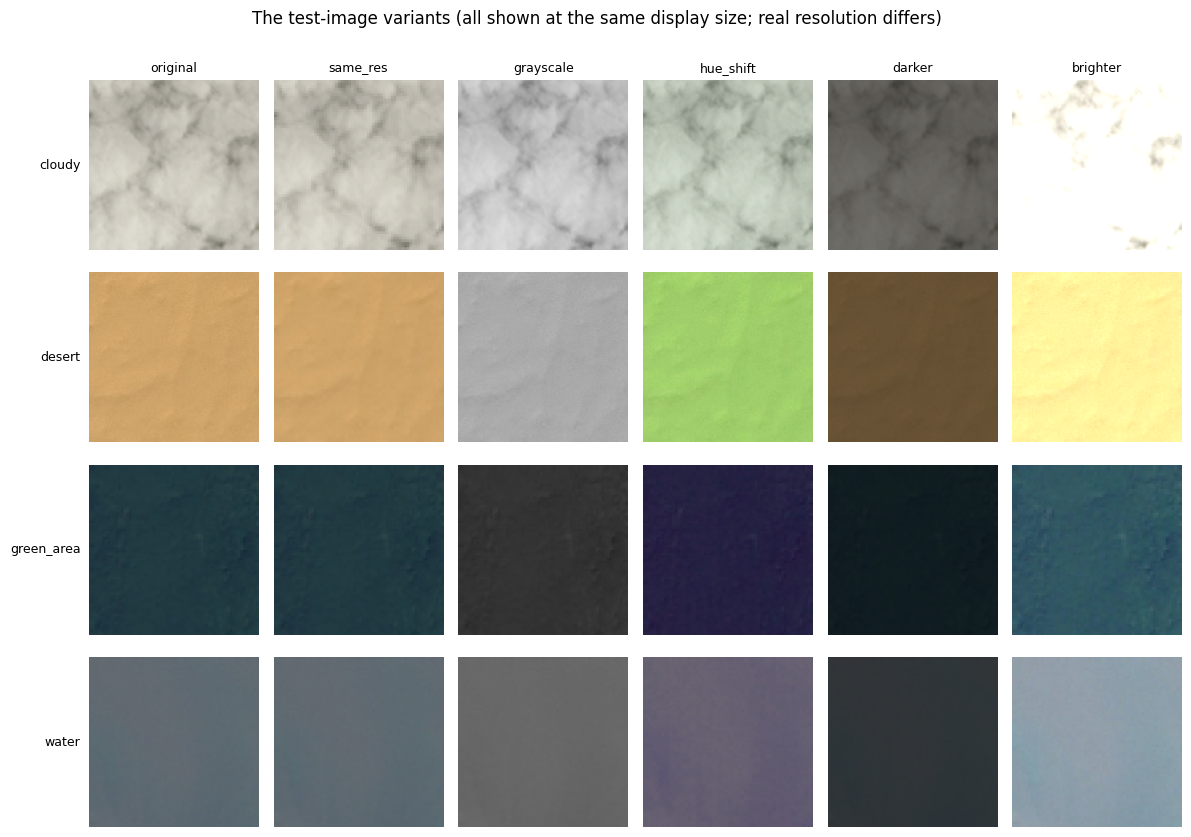

In [6]:
# Preview: one example per class under each variant (always look at your perturbations!)
rs = np.random.RandomState(SEED)
pick = [int(rs.choice(np.where(y_test == k)[0])) for k in range(len(CLASS_NAMES))]
fig, axes = plt.subplots(len(CLASS_NAMES), len(VARIANTS), figsize=(2.0 * len(VARIANTS), 2.1 * len(CLASS_NAMES)))
for i, k in enumerate(pick):
    for j, vname in enumerate(VARIANT_NAMES):
        ax = axes[i, j]
        ax.imshow(TEST_IMGS[vname][k].resize((128, 128), Image.NEAREST)); ax.axis("off")
        if i == 0: ax.set_title(vname, fontsize=9)
        if j == 0: ax.text(-0.05, 0.5, CLASS_NAMES[y_test[k]], transform=ax.transAxes, ha="right", va="center", fontsize=9)
plt.suptitle("The test-image variants (all shown at the same display size; real resolution differs)", y=1.0)
plt.tight_layout(); plt.savefig(FIG_DIR / "19_variants_preview.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. Load the models

1. **Fine-tuned ViT** from the folder saved by Notebook 3 (the seed chosen by validation score)
2. **CLIP ViT-B/32** (for zero-shot and the CLIP probe)
3. **DINOv2-base** (for the DINOv2 probe)

In [7]:
# [needs-torch]
import torch
import torchvision.transforms as T
from transformers import (AutoModelForImageClassification, AutoImageProcessor, CLIPModel, CLIPProcessor, AutoModel)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU"
print("Device:", DEVICE, "|", GPU_NAME)
if DEVICE == "cpu":
    print("WARNING: no GPU. Use Runtime -> Change runtime type -> T4 GPU, otherwise this will be slow.")
torch.manual_seed(SEED)

def find_model_dir():
    drv = Path("/content/drive/MyDrive/satellite_project")
    for c in [Path("/content/outputs_nb3/vit_best_model"), Path("/content/vit_best_model"),
              drv / "outputs_nb3" / "vit_best_model", drv / "vit_best_model"]:
        if (c / "config.json").exists():
            return c
    for z in [Path("/content/notebook3_outputs.zip"), drv / "notebook3_outputs.zip"]:
        if z.exists():
            print("Extracting", z)
            with zipfile.ZipFile(z) as zf:
                zf.extractall("/content/outputs_nb3")
            c = Path("/content/outputs_nb3/vit_best_model")
            if (c / "config.json").exists():
                return c
    raise FileNotFoundError(
        "Could not find the fine-tuned ViT folder (vit_best_model) from Notebook 3.\n"
        "FIX: put the folder 'vit_best_model' (or notebook3_outputs.zip) into the Files panel, or into "
        "My Drive/satellite_project/outputs_nb3/, then re-run this cell.")

MODEL_DIR = find_model_dir()
print("Fine-tuned ViT folder:", MODEL_DIR)
vit = AutoModelForImageClassification.from_pretrained(MODEL_DIR).to(DEVICE).eval()
vit_proc = AutoImageProcessor.from_pretrained(MODEL_DIR)
vit_labels = [vit.config.id2label[i] for i in range(len(vit.config.id2label))]
assert vit_labels == CLASS_NAMES, f"Class order mismatch: model has {vit_labels}, data has {CLASS_NAMES}"
print("ViT class order matches the dataset:", vit_labels)

vit_tf = T.Compose([T.Resize((224, 224), interpolation=T.InterpolationMode.BICUBIC),
                    T.ToTensor(), T.Normalize(vit_proc.image_mean, vit_proc.image_std)])

clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
dino_model = AutoModel.from_pretrained("facebook/dinov2-base").to(DEVICE).eval()
dino_proc = AutoImageProcessor.from_pretrained("facebook/dinov2-base")
print("All three models loaded.")

Device: cuda | Tesla T4
Fine-tuned ViT folder: /content/drive/MyDrive/satellite_project/outputs_nb3/vit_best_model


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViT class order matches the dataset: ['cloudy', 'desert', 'green_area', 'water']


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

All three models loaded.


In [8]:
# [needs-torch]
BATCH = 64

def _t(x):
    return x if isinstance(x, torch.Tensor) else x.pooler_output

@torch.no_grad()
def vit_logits_batch(batch):
    x = torch.stack([vit_tf(im) for im in batch]).to(DEVICE)
    with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=USE_AMP):
        return vit(pixel_values=x).logits.float().cpu().numpy()

@torch.no_grad()
def clip_embed_batch(batch):
    inp = clip_proc(images=batch, return_tensors="pt").to(DEVICE)
    f = _t(clip_model.get_image_features(**inp))
    return torch.nn.functional.normalize(f, dim=-1).cpu().numpy()

@torch.no_grad()
def dino_embed_batch(batch):
    inp = dino_proc(images=batch, return_tensors="pt").to(DEVICE)
    h = dino_model(**inp).last_hidden_state
    return torch.cat([h[:, 0], h[:, 1:].mean(dim=1)], dim=1).float().cpu().numpy()

def run_batched(imgs, fn, desc=""):
    return np.concatenate([fn(imgs[i:i + BATCH]) for i in tqdm(range(0, len(imgs), BATCH), desc=desc, leave=False)])

def run_paths(paths, fn, desc=""):
    out = []
    for i in tqdm(range(0, len(paths), BATCH), desc=desc, leave=False):
        out.append(fn([Image.open(p).convert("RGB") for p in paths[i:i + BATCH]]))
    return np.concatenate(out)
print("Inference helpers ready")

Inference helpers ready


## 4. Embeddings of the original images and the linear probes

The probes are trained on **original training images only**, exactly as in Notebook 2 (standardise, logistic regression, `C` chosen on validation). We load the embeddings saved by Notebook 2 if they match this table, otherwise we compute them.

In [9]:
# [needs-torch]
def try_load_embeddings(filename):
    drv = Path("/content/drive/MyDrive/satellite_project")
    for folder in [OUT_DIR / "embeddings", Path("/content/outputs_nb2/embeddings"), drv / "outputs_nb2" / "embeddings",
                   Path("/content/outputs/embeddings"), Path("/content"), Path("/content/drive/MyDrive"), drv]:
        f = folder / filename
        if f.exists():
            arr = np.load(f)
            if arr.shape[0] == len(df):
                print(f"Loaded {filename} from {folder}: {arr.shape}")
                return arr
            print(f"Ignoring {f}: {arr.shape[0]} rows, expected {len(df)}")
    return None

(OUT_DIR / "embeddings").mkdir(exist_ok=True)
EMB_CLIP = try_load_embeddings("clip_b32_images.npy")
if EMB_CLIP is None:
    EMB_CLIP = run_paths(df["path"].tolist(), clip_embed_batch, "CLIP embeddings")
    if not QUICK_TEST: np.save(OUT_DIR / "embeddings" / "clip_b32_images.npy", EMB_CLIP)
EMB_DINO = try_load_embeddings("dinov2_base_images.npy")
if EMB_DINO is None:
    EMB_DINO = run_paths(df["path"].tolist(), dino_embed_batch, "DINOv2 embeddings")
    if not QUICK_TEST: np.save(OUT_DIR / "embeddings" / "dinov2_base_images.npy", EMB_DINO)
print("Embeddings:", EMB_CLIP.shape, EMB_DINO.shape)

Loaded clip_b32_images.npy from /content/drive/MyDrive/satellite_project/outputs_nb2/embeddings: (5631, 512)
Loaded dinov2_base_images.npy from /content/drive/MyDrive/satellite_project/outputs_nb2/embeddings: (5631, 1536)
Embeddings: (5631, 512) (5631, 1536)


In [11]:
C_GRID = [0.001, 0.01, 0.1, 1, 10, 100]
PROBES = {}
for name, E in (("CLIP probe", EMB_CLIP), ("DINOv2 probe", EMB_DINO)):
    best = (-1, None)
    for C in C_GRID:
        p = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000)).fit(E[idx_train], y[idx_train])
        f1 = f1_score(y[idx_val], p.predict(E[idx_val]), average="macro")
        if f1 > best[0]:
            best = (f1, C)
    PROBES[name] = make_pipeline(StandardScaler(), LogisticRegression(C=best[1], max_iter=3000)).fit(E[idx_train], y[idx_train])
    print(f"{name}: chosen C = {best[1]} (validation macro-F1 {best[0]:.4f})")

CLIP probe: chosen C = 0.01 (validation macro-F1 1.0000)
DINOv2 probe: chosen C = 0.01 (validation macro-F1 0.9978)


### Zero-shot CLIP text prompts
We reuse the best prompt from Notebook 1 if `results_notebook1.json` is available. Otherwise we use the wording that worked best in the earlier run ("a satellite image taken from space showing ..." with rich class descriptions).

In [12]:
# [needs-torch]
CLASS_TEXT_PLAIN = {"cloudy": "clouds", "desert": "desert", "green_area": "green area", "water": "water"}
CLASS_TEXT_RICH  = {"cloudy": "clouds covering the ground", "desert": "desert with sand and bare rock",
                    "green_area": "green vegetation, forest or farmland", "water": "water such as sea, lake or river"}
TEMPLATES = {"plain": "{}", "photo": "a photo of {}.", "satellite": "a satellite photo of {}.",
             "aerial": "an aerial image of {}.", "from_space": "a satellite image taken from space showing {}."}

PROMPT_KEY = ("rich_names", "from_space")            # fallback
f1_json = find_optional("results_notebook1.json")
if f1_json:
    try:
        PROMPT_KEY = tuple(json.load(open(f1_json))["zero_shot_clip_b32"]["prompt"])
        print("Prompt from Notebook 1:", PROMPT_KEY)
    except Exception as e:
        print("Could not read the prompt from Notebook 1 (", e, ") - using fallback", PROMPT_KEY)
else:
    print("results_notebook1.json not found - using fallback prompt", PROMPT_KEY)

@torch.no_grad()
def clip_text_embed(prompts):
    inp = clip_proc(text=prompts, return_tensors="pt", padding=True).to(DEVICE)
    f = _t(clip_model.get_text_features(**inp))
    return torch.nn.functional.normalize(f, dim=-1).cpu().numpy()

wording, tname = PROMPT_KEY
ctext = CLASS_TEXT_PLAIN if wording == "plain_names" else CLASS_TEXT_RICH
if tname == "ENSEMBLE":
    te = np.mean([clip_text_embed([t.format(ctext[c]) for c in CLASS_NAMES]) for t in TEMPLATES.values()], axis=0)
    TXT_EMB = te / np.linalg.norm(te, axis=1, keepdims=True)
else:
    TXT_EMB = clip_text_embed([TEMPLATES[tname].format(ctext[c]) for c in CLASS_NAMES])

# Extra free-text queries for the text-to-image retrieval section
TEXT_QUERIES = [("a satellite image of a desert", "desert"), ("a satellite image of clouds", "cloudy"),
                ("a satellite image of a lake", "water"), ("a satellite image of a forest", "green_area"),
                ("a satellite image of the sea", "water"), ("a satellite image of farmland", "green_area")]
TXT_Q = clip_text_embed([q for q, _ in TEXT_QUERIES])
print("Text embeddings ready:", TXT_EMB.shape, TXT_Q.shape)

results_notebook1.json not found - using fallback prompt ('rich_names', 'from_space')
Text embeddings ready: (4, 512) (6, 512)


## 5. Run every model on every variant

For each variant of the test set we compute the fine-tuned ViT's outputs and the CLIP and DINOv2 embeddings once. The probes and the zero-shot classifier then predict from those embeddings. Results are cached to disk.

In [13]:
# [needs-torch]
cache = OUT_DIR / "variant_outputs.npz"
VARIANT_OUT = {}
if cache.exists() and not QUICK_TEST:
    z = np.load(cache)
    VARIANT_OUT = {v: dict(vit=z[f"{v}__vit"], clip=z[f"{v}__clip"], dino=z[f"{v}__dino"]) for v in VARIANT_NAMES}
    print("Loaded cached variant outputs")
else:
    for v in VARIANT_NAMES:
        VARIANT_OUT[v] = dict(vit=run_batched(TEST_IMGS[v], vit_logits_batch, f"{v}: ViT"),
                              clip=run_batched(TEST_IMGS[v], clip_embed_batch, f"{v}: CLIP"),
                              dino=run_batched(TEST_IMGS[v], dino_embed_batch, f"{v}: DINOv2"))
        print("done:", v)
    if not QUICK_TEST:
        np.savez(cache, **{f"{v}__{k}": a for v, d in VARIANT_OUT.items() for k, a in d.items()})

original: ViT:   0%|          | 0/14 [00:00<?, ?it/s]

original: CLIP:   0%|          | 0/14 [00:00<?, ?it/s]

original: DINOv2:   0%|          | 0/14 [00:00<?, ?it/s]

done: original


same_res: ViT:   0%|          | 0/14 [00:00<?, ?it/s]

...

done: darker


brighter: ViT:   0%|          | 0/14 [00:00<?, ?it/s]

brighter: CLIP:   0%|          | 0/14 [00:00<?, ?it/s]

brighter: DINOv2:   0%|          | 0/14 [00:00<?, ?it/s]

done: brighter


In [14]:
# Sanity checks: do the freshly computed "original" outputs agree with what Notebooks 2 and 3 produced?
d_clip = np.abs(VARIANT_OUT["original"]["clip"] - EMB_CLIP[idx_test]).max()
d_dino = np.abs(VARIANT_OUT["original"]["dino"] - EMB_DINO[idx_test]).max()
print(f"Max difference vs saved CLIP embeddings:   {d_clip:.5f}  (should be ~0)")
print(f"Max difference vs saved DINOv2 embeddings: {d_dino:.5f}  (should be ~0)")

vit_orig_pred = VARIANT_OUT["original"]["vit"].argmax(1)
print(f"Fine-tuned ViT accuracy on the original test images (recomputed here): {accuracy_score(y_test, vit_orig_pred):.4f}")
nb3_json = find_optional("results_notebook3.json")
if nb3_json and not QUICK_TEST:
    r3 = json.load(open(nb3_json))
    best_seed = str(r3["best_seed_by_val"])
    print(f"Notebook 3 reported for the best seed ({best_seed}): {r3['per_seed'][best_seed]['test_accuracy']:.4f}  "
          "(a tiny difference from fp16 rounding is normal)")
nb3_pred = find_optional("vit_test_predictions.csv")
if nb3_pred and not QUICK_TEST:
    p3 = pd.read_csv(nb3_pred)
    col = f"pred_seed{r3['best_seed_by_val']}" if nb3_json else None
    if col in p3.columns and len(p3) == len(idx_test):
        print(f"Agreement with Notebook 3's saved predictions: {(p3[col].values == vit_orig_pred).mean():.4f}  (should be ~1.0)")

Max difference vs saved CLIP embeddings:   0.00000  (should be ~0)
Max difference vs saved DINOv2 embeddings: 0.00020  (should be ~0)
Fine-tuned ViT accuracy on the original test images (recomputed here): 0.9988
Notebook 3 reported for the best seed (42): 0.9988  (a tiny difference from fp16 rounding is normal)
Agreement with Notebook 3's saved predictions: 1.0000  (should be ~1.0)


In [15]:
VARIANT_LABELS = {"original": "original", "same_res": "same resolution", "grayscale": "grayscale",
                  "hue_shift": "hue shift", "darker": "darker", "brighter": "brighter"}
MODELS = ["Zero-shot CLIP", "CLIP probe", "DINOv2 probe", "Fine-tuned ViT"]

PRED = {m: {} for m in MODELS}
for v in VARIANT_NAMES:
    o = VARIANT_OUT[v]
    PRED["Zero-shot CLIP"][v]  = (o["clip"] @ TXT_EMB.T).argmax(1)
    PRED["CLIP probe"][v]      = PROBES["CLIP probe"].predict(o["clip"])
    PRED["DINOv2 probe"][v]    = PROBES["DINOv2 probe"].predict(o["dino"])
    PRED["Fine-tuned ViT"][v]  = o["vit"].argmax(1)

rows = []
for m in MODELS:
    for v in VARIANT_NAMES:
        rows.append(dict(model=m, variant=v, accuracy=accuracy_score(y_test, PRED[m][v]),
                         macro_f1=f1_score(y_test, PRED[m][v], average="macro")))
METRICS = pd.DataFrame(rows)
print("ACCURACY (rows = model, columns = variant)")
print(METRICS.pivot(index="model", columns="variant", values="accuracy").loc[MODELS, VARIANT_NAMES].round(4).to_string())
print("\nMACRO-F1")
print(METRICS.pivot(index="model", columns="variant", values="macro_f1").loc[MODELS, VARIANT_NAMES].round(4).to_string())

ACCURACY (rows = model, columns = variant)
variant         original  same_res  grayscale  hue_shift  darker  brighter
model                                                                     
Zero-shot CLIP    0.7461    0.7355     0.5552     0.4045  0.6524    0.6180
CLIP probe        0.9988    0.8778     0.7699     0.8861  0.9063    0.8932
DINOv2 probe      0.9964    0.9846     0.8849     0.9834  0.9941    0.9905
Fine-tuned ViT    0.9988    0.9822     0.8992     0.9822  0.7580    0.8790

MACRO-F1
variant         original  same_res  grayscale  hue_shift  darker  brighter
model                                                                     
Zero-shot CLIP    0.7482    0.7376     0.5280     0.3732  0.6184    0.6302
CLIP probe        0.9989    0.8574     0.7407     0.8845  0.9124    0.8694
DINOv2 probe      0.9967    0.9842     0.8809     0.9838  0.9944    0.9911
Fine-tuned ViT    0.9989    0.9832     0.9010     0.9823  0.7668    0.8647


## 6. Robustness results

**Paired bootstrap for the accuracy drop.** Each variant uses the *same* test images as the original, so we resample the images together and look at `accuracy(variant) - accuracy(original)`. If the 95% interval is entirely below zero, the drop is real and not chance.

In [16]:
n_test = len(y_test)
BOOT_IDX = np.random.RandomState(SEED).randint(0, n_test, (N_BOOT, n_test))

def correct_of(m, v):
    return (PRED[m][v] == y_test).astype(float)

# CI of the accuracy in every cell
CI = {(m, v): np.percentile(correct_of(m, v)[BOOT_IDX].mean(1), [2.5, 97.5]) for m in MODELS for v in VARIANT_NAMES}

# Paired drop vs original
drop_rows = []
for m in MODELS:
    c0 = correct_of(m, "original")
    for v in VARIANT_NAMES[1:]:
        diff = correct_of(m, v) - c0
        lo, hi = np.percentile(diff[BOOT_IDX].mean(1), [2.5, 97.5])
        drop_rows.append(dict(model=m, variant=v, change=diff.mean(), ci_lo=lo, ci_hi=hi,
                              significant=bool(hi < 0 or lo > 0)))
DROP = pd.DataFrame(drop_rows)
print("CHANGE IN ACCURACY vs original (negative = worse), paired 95% bootstrap CI")
tab = DROP.assign(txt=lambda d: [f"{c:+.3f} [{l:+.3f},{h:+.3f}]{' *' if s else ''}" for c, l, h, s in zip(d.change, d.ci_lo, d.ci_hi, d.significant)])
print(tab.pivot(index="model", columns="variant", values="txt").loc[MODELS, VARIANT_NAMES[1:]].to_string())
print("\n* = interval excludes zero (change is unlikely to be chance)")

CHANGE IN ACCURACY vs original (negative = worse), paired 95% bootstrap CI
variant                         same_res                 grayscale                 hue_shift                    darker                  brighter
model                                                                                                                                           
Zero-shot CLIP    -0.011 [-0.023,+0.001]  -0.191 [-0.225,-0.157] *  -0.342 [-0.378,-0.305] *  -0.094 [-0.125,-0.064] *  -0.128 [-0.155,-0.100] *
CLIP probe      -0.121 [-0.145,-0.098] *  -0.229 [-0.259,-0.202] *  -0.113 [-0.134,-0.091] *  -0.093 [-0.113,-0.074] *  -0.106 [-0.127,-0.085] *
DINOv2 probe    -0.012 [-0.019,-0.005] *  -0.112 [-0.134,-0.091] *  -0.013 [-0.023,-0.004] *    -0.002 [-0.008,+0.002]  -0.006 [-0.012,-0.001] *
Fine-tuned ViT  -0.017 [-0.025,-0.008] *  -0.100 [-0.119,-0.079] *  -0.017 [-0.026,-0.008] *  -0.241 [-0.270,-0.212] *  -0.120 [-0.142,-0.098] *

* = interval excludes zero (change is unlikely to be c

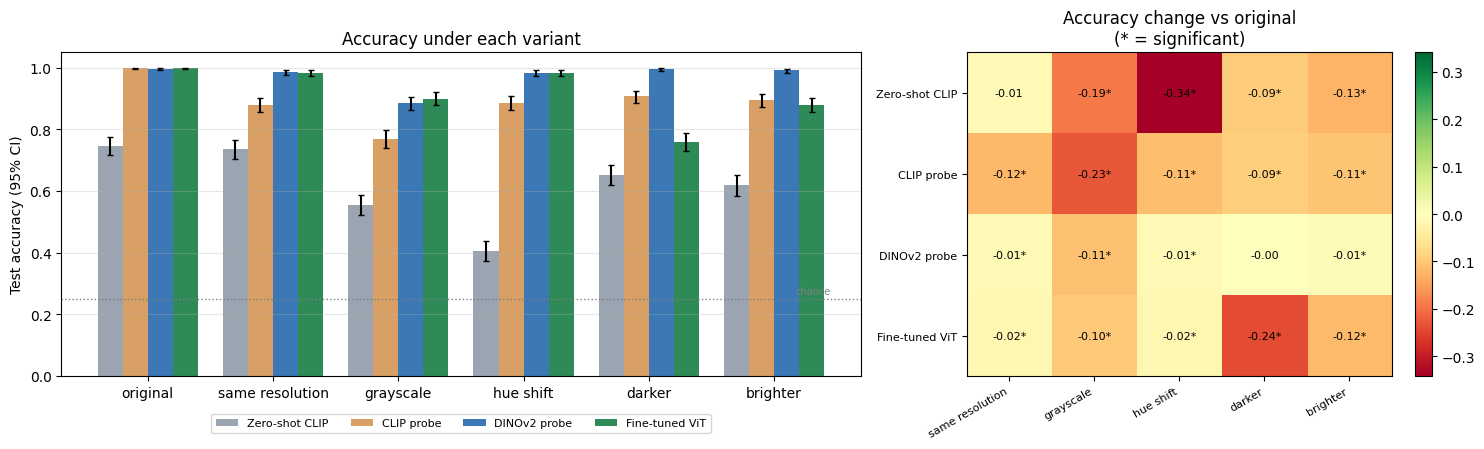

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.7, 1]})
ax = axes[0]
w = 0.2; x = np.arange(len(VARIANT_NAMES))
colors = ["#9aa5b1", "#d9a066", "#3b78b5", "#2e8b57"]
for k, m in enumerate(MODELS):
    accs = np.array([accuracy_score(y_test, PRED[m][v]) for v in VARIANT_NAMES])
    lo = np.array([CI[(m, v)][0] for v in VARIANT_NAMES]); hi = np.array([CI[(m, v)][1] for v in VARIANT_NAMES])
    ax.bar(x + (k - 1.5) * w, accs, w, yerr=[accs - lo, hi - accs], capsize=2, label=m, color=colors[k])
ax.set_xticks(x); ax.set_xticklabels([VARIANT_LABELS[v] for v in VARIANT_NAMES])
ax.set_ylim(0, 1.05); ax.set_ylabel("Test accuracy (95% CI)"); ax.axhline(0.25, ls=":", color="grey", lw=1)
ax.text(len(x) - 0.55, 0.265, "chance", fontsize=7, color="grey", ha="right")
ax.set_title("Accuracy under each variant"); ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4); ax.grid(axis="y", alpha=0.3)

ax = axes[1]
H = DROP.pivot(index="model", columns="variant", values="change").loc[MODELS, VARIANT_NAMES[1:]]
vmax = max(0.05, np.abs(H.values).max())
im = ax.imshow(H.values, cmap="RdYlGn", vmin=-vmax, vmax=vmax, aspect="auto")
ax.set_xticks(range(H.shape[1])); ax.set_xticklabels([VARIANT_LABELS[v] for v in H.columns], rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(H.shape[0])); ax.set_yticklabels(H.index, fontsize=8)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        sig = DROP[(DROP.model == H.index[i]) & (DROP.variant == H.columns[j])]["significant"].iloc[0]
        ax.text(j, i, f"{H.values[i, j]:+.2f}{'*' if sig else ''}", ha="center", va="center", fontsize=8)
ax.set_title("Accuracy change vs original\n(* = significant)")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.savefig(FIG_DIR / "20_robustness_accuracy.png", dpi=150); plt.show()

### 6.1 The resolution-shortcut test, in detail

Because `cloudy`/`desert` images are 256x256 and `green_area`/`water` images are 64x64, we can separate two kinds of error:
- **Cross-group error:** a 256x256-class image is predicted as a 64x64 class (or vice versa), e.g. desert -> water. This is exactly what a resolution shortcut would cause.
- **Within-group error:** e.g. cloudy <-> desert, or green_area <-> water. This is ordinary visual confusion.

If the **cross-group error rate jumps under `same_res`**, the model was using resolution or sharpness as a cue. We also show per-class recall and confusion matrices under `same_res`.

CROSS-GROUP error rate (fraction of ALL test images predicted in a class of the other native resolution)
variant         original  same_res  grayscale  hue_shift  darker  brighter
model                                                                     
Zero-shot CLIP    0.1198    0.1222     0.3203     0.5350  0.1139    0.2883
CLIP probe        0.0000    0.1198     0.0308     0.0047  0.0225    0.0024
DINOv2 probe      0.0000    0.0059     0.1032     0.0119  0.0024    0.0059
Fine-tuned ViT    0.0000    0.0166     0.0617     0.0059  0.1934    0.0320

WITHIN-GROUP error rate (ordinary confusions inside a resolution group)
variant         original  same_res  grayscale  hue_shift  darker  brighter
model                                                                     
Zero-shot CLIP    0.1340    0.1423     0.1246     0.0605  0.2337    0.0937
CLIP probe        0.0012    0.0024     0.1993     0.1091  0.0712    0.1044
DINOv2 probe      0.0036    0.0095     0.0119     0.0047  0.0036    0.00

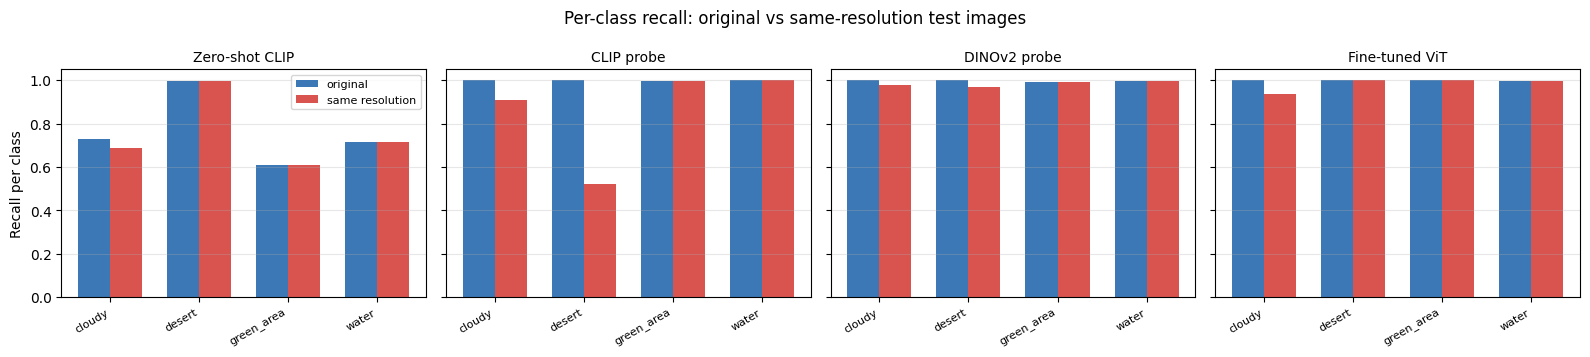

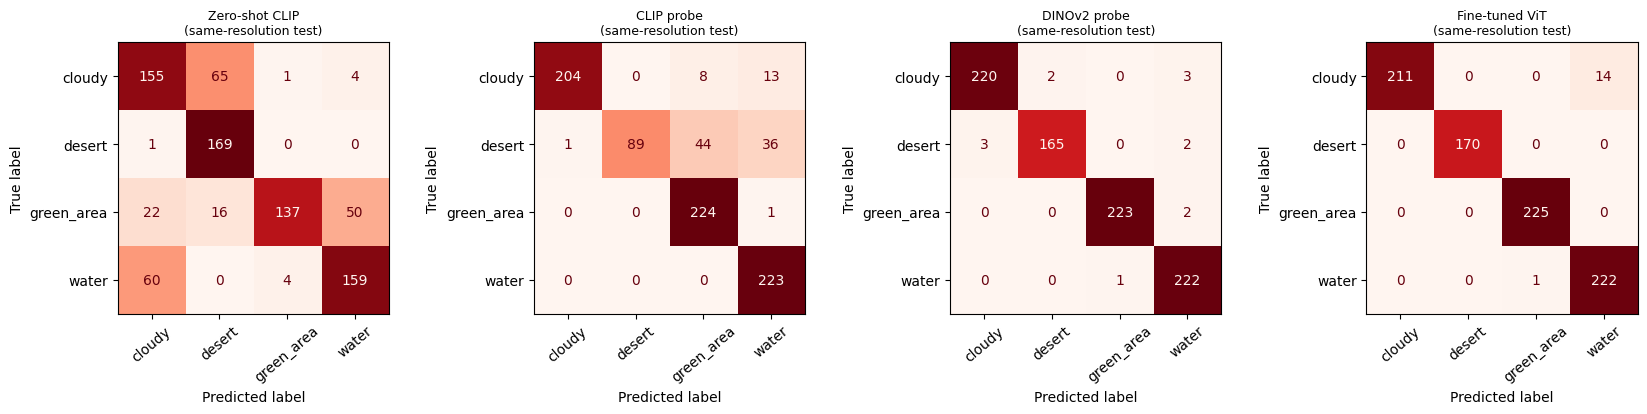

In [18]:
def error_split(pred):
    true_g, pred_g = CLASS_GROUP[y_test], CLASS_GROUP[pred]
    wrong = pred != y_test
    return float((wrong & (true_g != pred_g)).mean()), float((wrong & (true_g == pred_g)).mean())

rows = []
for m in MODELS:
    for v in VARIANT_NAMES:
        cross, within = error_split(PRED[m][v])
        rows.append(dict(model=m, variant=v, cross_group_error=cross, within_group_error=within))
GROUP_ERR = pd.DataFrame(rows)
print("CROSS-GROUP error rate (fraction of ALL test images predicted in a class of the other native resolution)")
print(GROUP_ERR.pivot(index="model", columns="variant", values="cross_group_error").loc[MODELS, VARIANT_NAMES].round(4).to_string())
print("\nWITHIN-GROUP error rate (ordinary confusions inside a resolution group)")
print(GROUP_ERR.pivot(index="model", columns="variant", values="within_group_error").loc[MODELS, VARIANT_NAMES].round(4).to_string())

# Per-class recall: original vs same_res
rec = {}
for m in MODELS:
    for v in ("original", "same_res"):
        cm = confusion_matrix(y_test, PRED[m][v], labels=range(len(CLASS_NAMES)))
        rec[(m, v)] = np.diag(cm) / cm.sum(1).clip(min=1)
fig, axes = plt.subplots(1, len(MODELS), figsize=(4.0 * len(MODELS), 3.6), sharey=True)
xk = np.arange(len(CLASS_NAMES))
for ax, m in zip(axes, MODELS):
    ax.bar(xk - 0.18, rec[(m, "original")], 0.36, label="original", color="#3b78b5")
    ax.bar(xk + 0.18, rec[(m, "same_res")], 0.36, label="same resolution", color="#d9534f")
    ax.set_xticks(xk); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right", fontsize=8)
    ax.set_title(m, fontsize=10); ax.set_ylim(0, 1.05); ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Recall per class"); axes[0].legend(fontsize=8)
plt.suptitle("Per-class recall: original vs same-resolution test images"); plt.tight_layout()
plt.savefig(FIG_DIR / "21_same_res_recall.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, len(MODELS), figsize=(4.2 * len(MODELS), 4.0))
for ax, m in zip(axes, MODELS):
    ConfusionMatrixDisplay(confusion_matrix(y_test, PRED[m]["same_res"], labels=range(len(CLASS_NAMES))),
                           display_labels=CLASS_NAMES).plot(ax=ax, cmap="Reds", colorbar=False, xticks_rotation=40)
    ax.set_title(f"{m}\n(same-resolution test)", fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / "22_same_res_confusion.png", dpi=150); plt.show()

## 7. Are the models really different? (statistics on the original test set)

For every pair of models, on the **same 843 test images**:
- **Paired bootstrap:** the interval of the accuracy difference. If it excludes 0, the difference is not just chance.
- **McNemar's exact test:** looks only at the images where exactly one of the two models is correct (b = only model A right, c = only model B right) and asks whether b and c are balanced. The p-values are also **Bonferroni-corrected** for the 6 comparisons.

If an interval includes 0 or p is large, you **cannot claim** one model is better, and saying so is a valid result.

In [19]:
def mcnemar_exact(b, c):
    n = b + c
    if n == 0:
        return 1.0
    k = min(b, c)
    return min(1.0, 2.0 * sum(math.comb(n, i) for i in range(k + 1)) / 2 ** n)

pair_rows = []
pairs = list(combinations(MODELS, 2))
for A, B in pairs:
    ca, cb = correct_of(A, "original"), correct_of(B, "original")
    diff = ca - cb
    lo, hi = np.percentile(diff[BOOT_IDX].mean(1), [2.5, 97.5])
    b_cnt, c_cnt = int(((ca == 1) & (cb == 0)).sum()), int(((ca == 0) & (cb == 1)).sum())
    p = mcnemar_exact(b_cnt, c_cnt)
    pair_rows.append(dict(A=A, B=B, acc_A=ca.mean(), acc_B=cb.mean(), diff=diff.mean(), ci_lo=lo, ci_hi=hi,
                          only_A_right=b_cnt, only_B_right=c_cnt, p_mcnemar=p,
                          p_bonferroni=min(1.0, p * len(pairs))))
PAIRS = pd.DataFrame(pair_rows)
PAIRS["verdict"] = np.where(PAIRS["p_bonferroni"] < 0.05, "different", "no clear difference")
print(PAIRS.round(4).to_string(index=False))

             A              B  acc_A  acc_B    diff   ci_lo   ci_hi  only_A_right  only_B_right  p_mcnemar  p_bonferroni             verdict
Zero-shot CLIP     CLIP probe 0.7461 0.9988 -0.2527 -0.2835 -0.2242             1           214      0.000           0.0           different
Zero-shot CLIP   DINOv2 probe 0.7461 0.9964 -0.2503 -0.2811 -0.2218             1           212      0.000           0.0           different
Zero-shot CLIP Fine-tuned ViT 0.7461 0.9988 -0.2527 -0.2835 -0.2242             1           214      0.000           0.0           different
    CLIP probe   DINOv2 probe 0.9988 0.9964  0.0024 -0.0024  0.0071             3             1      0.625           1.0 no clear difference
    CLIP probe Fine-tuned ViT 0.9988 0.9988  0.0000 -0.0036  0.0036             1             1      1.000           1.0 no clear difference
  DINOv2 probe Fine-tuned ViT 0.9964 0.9988 -0.0024 -0.0059  0.0000             0             2      0.500           1.0 no clear difference


## 8. Image retrieval

**Image-to-image:** each test image is a *query*; we search the **training images** (the gallery) for its nearest neighbours by cosine similarity of embeddings, using the frozen CLIP and DINOv2 features. **Precision@K** = the share of the top-K results that have the same class as the query. A random search would score about 0.25.

**Text-to-image (CLIP only):** a text query such as "a satellite image of a desert" is embedded and used to rank the test images. We measure how many of the top results really belong to the intended class.

In [20]:
def l2norm(a):
    return a / np.linalg.norm(a, axis=1, keepdims=True).clip(min=1e-12)

KS = [1, 5, 10, 20]
RETR = {}
for name, E in (("CLIP", EMB_CLIP), ("DINOv2", EMB_DINO)):
    Q, G = l2norm(E[idx_test]), l2norm(E[idx_train])
    sims = Q @ G.T
    order = np.argsort(-sims, axis=1)[:, :max(KS)]
    hits = (y[idx_train][order] == y_test[:, None])
    RETR[name] = dict(order=order, **{f"P@{k}": float(hits[:, :k].mean()) for k in KS})
    per_class = {c: float(hits[y_test == i, :10].mean()) for i, c in enumerate(CLASS_NAMES)}
    RETR[name]["per_class_P@10"] = per_class

retr_df = pd.DataFrame({n: {k: RETR[n][k] for k in [f"P@{k}" for k in KS]} for n in RETR}).T
print("Image-to-image retrieval (queries = test images, gallery = training images)")
print(retr_df.round(4).to_string())
print("\nPrecision@10 per class")
print(pd.DataFrame({n: RETR[n]["per_class_P@10"] for n in RETR}).round(4).to_string())
print("\nChance level is about", round(float(np.mean([(y[idx_train] == k).mean() for k in range(len(CLASS_NAMES))])), 2))

Image-to-image retrieval (queries = test images, gallery = training images)
           P@1     P@5    P@10    P@20
CLIP    0.9917  0.9881  0.9841  0.9777
DINOv2  0.9953  0.9891  0.9832  0.9791

Precision@10 per class
              CLIP  DINOv2
cloudy      0.9956  0.9893
desert      0.9994  0.9971
green_area  0.9969  0.9947
water       0.9480  0.9547

Chance level is about 0.25


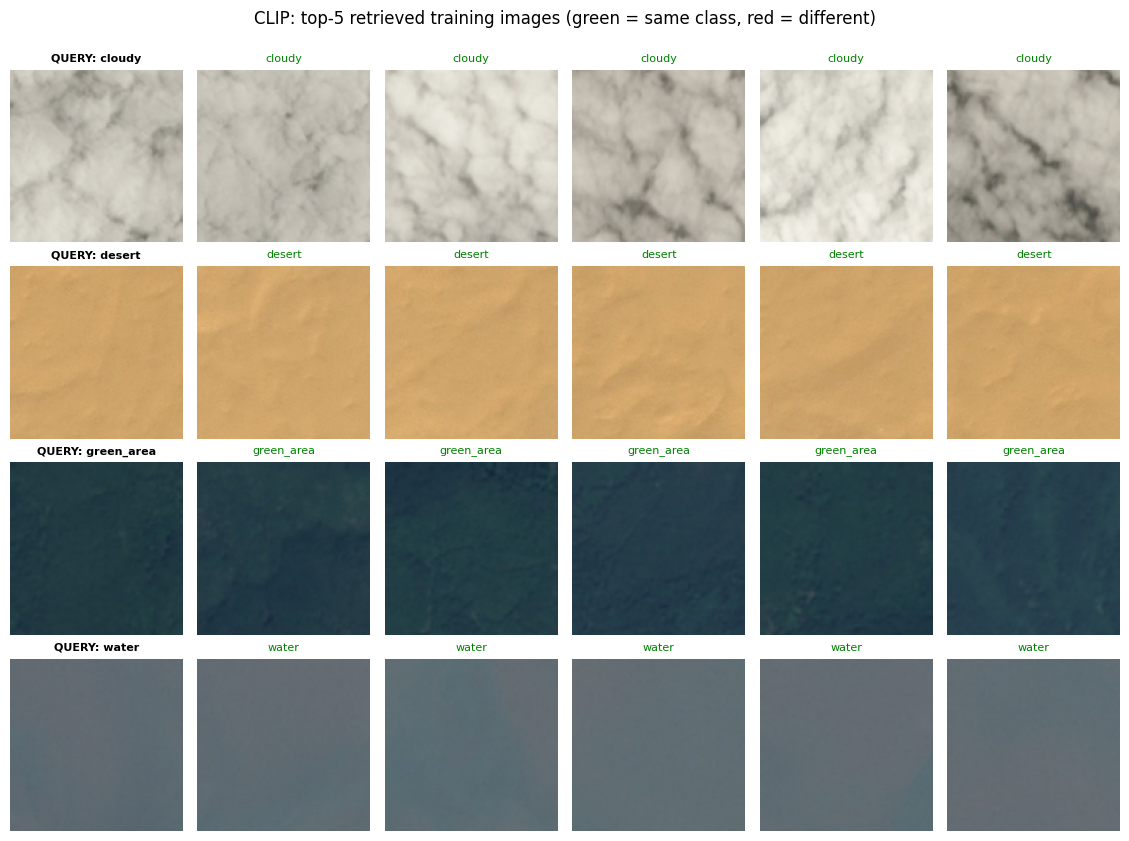

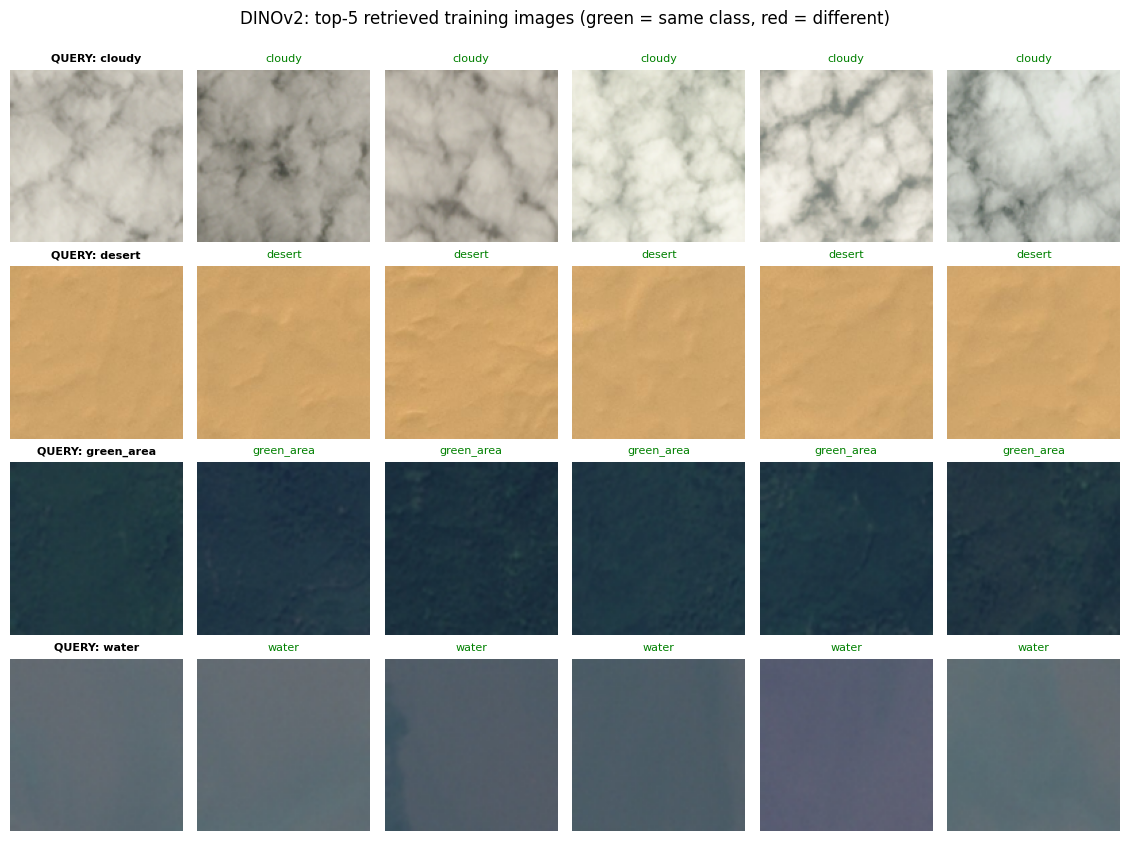

In [21]:
def show_retrieval(name, n_show=4, k=5):
    rs = np.random.RandomState(SEED)
    qpos = [int(rs.choice(np.where(y_test == c)[0])) for c in range(min(n_show, len(CLASS_NAMES)))]
    fig, axes = plt.subplots(len(qpos), k + 1, figsize=(1.9 * (k + 1), 2.1 * len(qpos)))
    for r, qi in enumerate(qpos):
        axes[r, 0].imshow(Image.open(test_paths[qi]).convert("RGB").resize((128, 128)))
        axes[r, 0].set_title(f"QUERY: {CLASS_NAMES[y_test[qi]]}", fontsize=8, fontweight="bold"); axes[r, 0].axis("off")
        for j in range(k):
            gi = idx_train[RETR[name]["order"][qi, j]]
            ax = axes[r, j + 1]
            ax.imshow(Image.open(df.loc[gi, "path"]).convert("RGB").resize((128, 128)))
            ok = y[gi] == y_test[qi]
            ax.set_title(df.loc[gi, "cls"], fontsize=8, color="green" if ok else "red"); ax.axis("off")
            for sp in ax.spines.values(): sp.set_visible(False)
    plt.suptitle(f"{name}: top-{k} retrieved training images (green = same class, red = different)", y=1.0)
    plt.tight_layout(); plt.savefig(FIG_DIR / f"23_retrieval_{name.lower()}.png", dpi=150, bbox_inches="tight"); plt.show()

show_retrieval("CLIP"); show_retrieval("DINOv2")

Text-to-image retrieval (CLIP): share of the top-K images that really show the target class
                        query target_class  P@10  P@50  n_relevant
        [class prompt] cloudy       cloudy   1.0  0.68         225
        [class prompt] desert       desert   1.0  0.92         170
    [class prompt] green_area   green_area   1.0  0.98         225
         [class prompt] water        water   0.0  0.14         223
a satellite image of a desert       desert   1.0  0.90         170
  a satellite image of clouds       cloudy   1.0  0.96         225
  a satellite image of a lake        water   0.0  0.08         223
a satellite image of a forest   green_area   1.0  0.98         225
 a satellite image of the sea        water   0.1  0.16         223
a satellite image of farmland   green_area   1.0  0.96         225

Mean P@10: 0.71 | mean P@50: 0.676


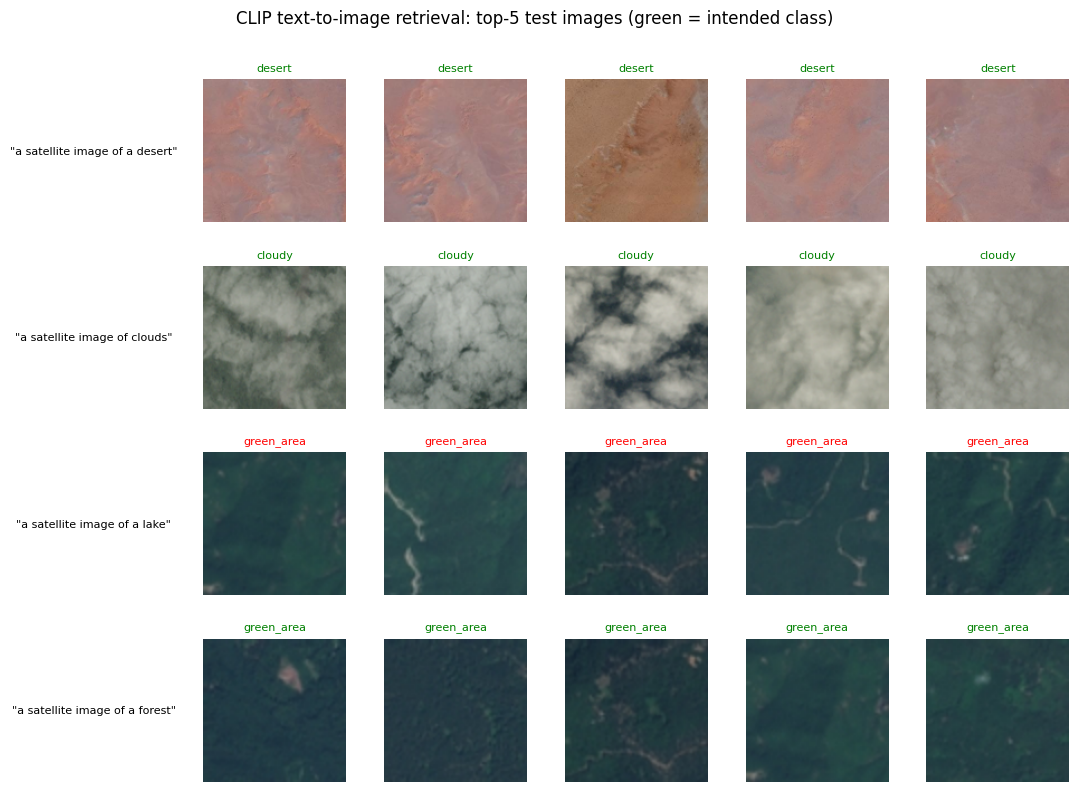

In [22]:
# Text-to-image retrieval with CLIP: rank the ORIGINAL test images by similarity to the text
img_emb = VARIANT_OUT["original"]["clip"]
queries = [(f"[class prompt] {c}", TXT_EMB[i], c) for i, c in enumerate(CLASS_NAMES)] + \
          [(q, TXT_Q[i], cls) for i, (q, cls) in enumerate(TEXT_QUERIES)]
tt_rows, ranked = [], {}
for text, emb, target in queries:
    order = np.argsort(-(img_emb @ emb))
    t_idx = CLASS_NAMES.index(target)
    ranked[text] = order
    tt_rows.append(dict(query=text, target_class=target,
                        **{f"P@{k}": float((y_test[order[:k]] == t_idx).mean()) for k in (10, 50)},
                        n_relevant=int((y_test == t_idx).sum())))
TT = pd.DataFrame(tt_rows)
print("Text-to-image retrieval (CLIP): share of the top-K images that really show the target class")
print(TT.round(3).to_string(index=False))
print("\nMean P@10:", round(TT["P@10"].mean(), 3), "| mean P@50:", round(TT["P@50"].mean(), 3))

show_q = [q for q, _ in TEXT_QUERIES[:4]]
fig, axes = plt.subplots(len(show_q), 6, figsize=(11, 2.0 * len(show_q)))
for r, text in enumerate(show_q):
    target = dict(TEXT_QUERIES)[text]
    axes[r, 0].text(0.5, 0.5, f'"{text}"', ha="center", va="center", fontsize=8, wrap=True); axes[r, 0].axis("off")
    for j in range(5):
        ii = ranked[text][j]
        ax = axes[r, j + 1]
        ax.imshow(TEST_IMGS["original"][ii].resize((128, 128))); ax.axis("off")
        ax.set_title(CLASS_NAMES[y_test[ii]], fontsize=8, color="green" if CLASS_NAMES[y_test[ii]] == target else "red")
plt.suptitle("CLIP text-to-image retrieval: top-5 test images (green = intended class)", y=1.0)
plt.tight_layout(); plt.savefig(FIG_DIR / "24_text_to_image.png", dpi=150, bbox_inches="tight"); plt.show()

## 9. UMAP of the embeddings

UMAP squeezes the high-dimensional embeddings into 2D so we can see how the models organise the images. We colour by **class** (do the classes form clean clusters?) and by **native image size** (does the layout also follow resolution?). Because size and class are confounded in this dataset, the two colourings look alike. That is exactly the confound the same-resolution test above addresses.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


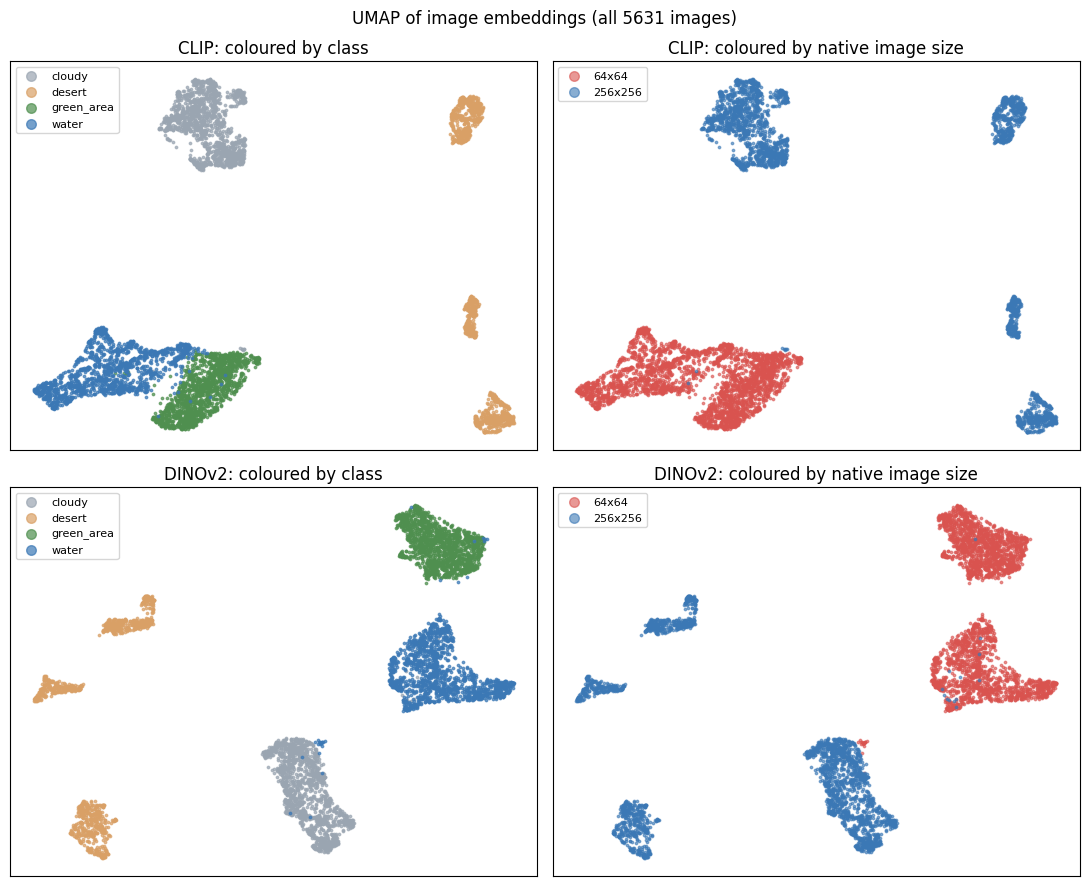

In [23]:
from sklearn.decomposition import PCA
try:
    import umap
    def embed_2d(E):
        Z = PCA(n_components=min(50, E.shape[1]), random_state=SEED).fit_transform(E)
        return umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.2, metric="cosine", random_state=SEED).fit_transform(Z)
    PROJ = "UMAP"
except Exception as e:
    print("umap-learn not available (", e, ") - falling back to t-SNE")
    from sklearn.manifold import TSNE
    def embed_2d(E):
        Z = PCA(n_components=min(50, E.shape[1]), random_state=SEED).fit_transform(E)
        return TSNE(n_components=2, random_state=SEED, init="pca", perplexity=30).fit_transform(Z)
    PROJ = "t-SNE"

class_colors = ["#9aa5b1", "#d9a066", "#4f8f4f", "#3b78b5"]
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for r, (name, E) in enumerate((("CLIP", EMB_CLIP), ("DINOv2", EMB_DINO))):
    XY = embed_2d(E)
    for k, c in enumerate(CLASS_NAMES):
        m = y == k
        axes[r, 0].scatter(XY[m, 0], XY[m, 1], s=3, color=class_colors[k % 4], label=c, alpha=0.7)
    axes[r, 0].set_title(f"{name}: coloured by class"); axes[r, 0].legend(markerscale=4, fontsize=8)
    for w_, col in zip(sorted(df["width"].unique()), ["#d9534f", "#3b78b5"]):
        m = (df["width"] == w_).values
        axes[r, 1].scatter(XY[m, 0], XY[m, 1], s=3, color=col, label=f"{w_}x{w_}", alpha=0.6)
    axes[r, 1].set_title(f"{name}: coloured by native image size"); axes[r, 1].legend(markerscale=4, fontsize=8)
    for ax in axes[r]:
        ax.set_xticks([]); ax.set_yticks([])
plt.suptitle(f"{PROJ} of image embeddings (all {len(df)} images)"); plt.tight_layout()
plt.savefig(FIG_DIR / "25_embedding_projection.png", dpi=150); plt.show()

## 10. Hard cases and error analysis

Images that **several models get wrong** are the interesting ones: they are usually ambiguous scenes, very dark or blurry images, or images whose label looks questionable. **Your task:** categorise 30-50 of them by hand (ambiguous scene / dark or blurry / label looks wrong / genuine model failure) and put the counts in your report.

In [24]:
wrong_matrix = np.stack([PRED[m]["original"] != y_test for m in MODELS], axis=1)     # (n_test, 4)
n_wrong = wrong_matrix.sum(1)
print("Number of models that get an image wrong (original test images):")
print(pd.Series(n_wrong).value_counts().sort_index().rename("images").to_string())
print(f"\nAll {len(MODELS)} models wrong: {int((n_wrong == len(MODELS)).sum())} images "
      f"| fine-tuned ViT wrong while all probes/zero-shot right: {int((wrong_matrix[:, 3] & ~wrong_matrix[:, :3].any(1)).sum())}")

hard = np.where(n_wrong >= 3)[0]
print(f"{len(hard)} images where at least 3 of 4 models fail")
if len(hard):
    pick = np.random.RandomState(SEED).choice(hard, min(18, len(hard)), replace=False)
    cols = 6; rws = int(np.ceil(len(pick) / cols))
    fig, axes = plt.subplots(rws, cols, figsize=(2.3 * cols, 2.8 * rws))
    axes = np.atleast_1d(axes).flatten()
    for ax in axes: ax.axis("off")
    for ax, k in zip(axes, pick):
        ax.imshow(TEST_IMGS["original"][k])
        ax.set_title(f"true: {CLASS_NAMES[y_test[k]]}\nViT: {CLASS_NAMES[PRED['Fine-tuned ViT']['original'][k]]}\n"
                     f"DINOv2: {CLASS_NAMES[PRED['DINOv2 probe']['original'][k]]} [{df.loc[idx_test[k], 'size']}]",
                     fontsize=7.5, color="crimson")
    plt.suptitle("Hard cases: at least 3 of 4 models wrong", y=1.0)
    plt.tight_layout(); plt.savefig(FIG_DIR / "26_hard_cases.png", dpi=150, bbox_inches="tight"); plt.show()

Number of models that get an image wrong (original test images):
0    627
1    213
2      3

All 4 models wrong: 0 images | fine-tuned ViT wrong while all probes/zero-shot right: 0
0 images where at least 3 of 4 models fail


## 11. Automatic summary and saving

The summary below states in words what the numbers show. **Check every sentence against the tables and figures** before using it, and add your interpretation (why might this happen?).

In [25]:
print("=" * 70); print("SUMMARY"); print("=" * 70)
for m in MODELS:
    o = accuracy_score(y_test, PRED[m]["original"])
    d = DROP[DROP.model == m].sort_values("change").iloc[0]
    sr = DROP[(DROP.model == m) & (DROP.variant == "same_res")].iloc[0]
    cg0 = GROUP_ERR[(GROUP_ERR.model == m) & (GROUP_ERR.variant == "original")]["cross_group_error"].iloc[0]
    cg1 = GROUP_ERR[(GROUP_ERR.model == m) & (GROUP_ERR.variant == "same_res")]["cross_group_error"].iloc[0]
    print(f"\n{m}: original accuracy {o:.3f}.")
    print(f"  Largest drop: '{d.variant}' ({d.change:+.3f}, 95% CI [{d.ci_lo:+.3f}, {d.ci_hi:+.3f}]"
          f"{', significant' if d.significant else ', not significant'}).")
    print(f"  Same-resolution test: accuracy change {sr.change:+.3f}"
          f"{' (significant)' if sr.significant else ' (not significant)'}; cross-group error {cg0:.3f} -> {cg1:.3f}.")
best_model = max(MODELS, key=lambda m: accuracy_score(y_test, PRED[m]["original"]))
print(f"\nBest model on the original test set: {best_model}.")
print("Pairs with a clear difference after Bonferroni correction:",
      [f"{r.A} vs {r.B}" for r in PAIRS.itertuples() if r.p_bonferroni < 0.05] or "none")
print("Retrieval Precision@10:", {n: round(RETR[n]["P@10"], 3) for n in RETR})

SUMMARY

Zero-shot CLIP: original accuracy 0.746.
  Largest drop: 'hue_shift' (-0.342, 95% CI [-0.378, -0.305], significant).
  Same-resolution test: accuracy change -0.011 (not significant); cross-group error 0.120 -> 0.122.

CLIP probe: original accuracy 0.999.
  Largest drop: 'grayscale' (-0.229, 95% CI [-0.259, -0.202], significant).
  Same-resolution test: accuracy change -0.121 (significant); cross-group error 0.000 -> 0.120.

DINOv2 probe: original accuracy 0.996.
  Largest drop: 'grayscale' (-0.112, 95% CI [-0.134, -0.091], significant).
  Same-resolution test: accuracy change -0.012 (significant); cross-group error 0.000 -> 0.006.

Fine-tuned ViT: original accuracy 0.999.
  Largest drop: 'darker' (-0.241, 95% CI [-0.270, -0.212], significant).
  Same-resolution test: accuracy change -0.017 (significant); cross-group error 0.000 -> 0.017.

Best model on the original test set: CLIP probe.
Pairs with a clear difference after Bonferroni correction: ['Zero-shot CLIP vs CLIP probe',

In [26]:
def jsonable(o):
    if isinstance(o, dict):  return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [jsonable(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, np.ndarray): return o.tolist()
    return o

results = {
    "quick_test": bool(QUICK_TEST), "n_test": int(n_test), "variants": VARIANT_NAMES, "models": MODELS,
    "accuracy": {m: {v: float(accuracy_score(y_test, PRED[m][v])) for v in VARIANT_NAMES} for m in MODELS},
    "macro_f1": {m: {v: float(f1_score(y_test, PRED[m][v], average="macro")) for v in VARIANT_NAMES} for m in MODELS},
    "accuracy_ci95": {m: {v: [float(x) for x in CI[(m, v)]] for v in VARIANT_NAMES} for m in MODELS},
    "drop_vs_original": DROP.to_dict(orient="records"),
    "group_errors": GROUP_ERR.to_dict(orient="records"),
    "pairwise_tests": PAIRS.to_dict(orient="records"),
    "retrieval_image_to_image": {n: {k: v for k, v in RETR[n].items() if k != "order"} for n in RETR},
    "retrieval_text_to_image": TT.to_dict(orient="records"),
    "prompt_used": list(PROMPT_KEY),
}
with open(OUT_DIR / "results_notebook4.json", "w") as f:
    json.dump(jsonable(results), f, indent=2)
METRICS.to_csv(OUT_DIR / "robustness_metrics.csv", index=False)
DROP.to_csv(OUT_DIR / "robustness_drops.csv", index=False)
PAIRS.to_csv(OUT_DIR / "pairwise_tests.csv", index=False)
print("Saved results to", OUT_DIR)

try:
    DRIVE_BACKUP_DIR.mkdir(parents=True, exist_ok=True)
    shutil.copytree(OUT_DIR, DRIVE_BACKUP_DIR / "outputs_nb4", dirs_exist_ok=True)
    print("Backed up to Google Drive:", DRIVE_BACKUP_DIR / "outputs_nb4")
except Exception as e:
    print("Drive backup skipped:", e)
shutil.make_archive("/content/notebook4_outputs", "zip", OUT_DIR)
print("Also created /content/notebook4_outputs.zip (download from the Files panel).")
if QUICK_TEST:
    print("\n*** QUICK TEST finished: the code works. Set QUICK_TEST = False and run everything again for real results. ***")

Saved results to /content/outputs_nb4
Backed up to Google Drive: /content/drive/MyDrive/satellite_project/outputs_nb4
Also created /content/notebook4_outputs.zip (download from the Files panel).
